In [ ]:
!pip install yfinance pandas numpy matplotlib

In [ ]:
import yfinance as yf

stock = yf.download("TCS.NS", period="1mo")

print(stock.tail())

/tmp/ipykernel_1060/1681558146.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download("TCS.NS", period="1mo")
[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open   Volume
Ticker           TCS.NS       TCS.NS       TCS.NS       TCS.NS   TCS.NS
Date                                                                   
2026-11-02  2501.699951  2549.899902  2492.899902  2523.000000  2817192
2026-11-03  2499.100098  2532.000000  2480.000000  2520.000000  3488517
2026-11-04  2436.000000  2493.800049  2420.000000  2481.399902  3142051
2026-11-05  2495.699951  2521.800049  2475.000000  2479.000000  6767948
2026-11-06  2498.500000  2565.000000  2489.600098  2533.600098  4922308


       TRADING BOT RESULTS
Stock Name: TCS.NS
Latest Date: 2026-11-06
Closing Price: Rs. 2498.5
Current Strategy Signal: BUY

Recent Trading Actions:
Price             Close       SMA_20       SMA_50 Action
Date                                                    
2026-10-26  2535.000000  2238.998792  2242.097480   HOLD
2026-10-27  2496.899902  2260.294263  2244.786655    BUY
2026-10-28  2460.000000  2280.306750  2247.016353   HOLD
2026-10-29  2478.000000  2303.124109  2250.556997   HOLD
2026-10-30  2502.600098  2326.266284  2255.250127   HOLD
2026-11-02  2501.699951  2348.149902  2259.746206   HOLD
2026-11-03  2499.100098  2367.943958  2264.011240   HOLD
2026-11-04  2436.000000  2385.299194  2266.934697   HOLD
2026-11-05  2495.699951  2406.619214  2271.408257   HOLD
2026-11-06  2498.500000  2428.293103  2275.697100   HOLD

Initial Capital: Rs. 100000
Final Portfolio Value: Rs. 86173.25
Profit / Loss: Rs. -13826.75


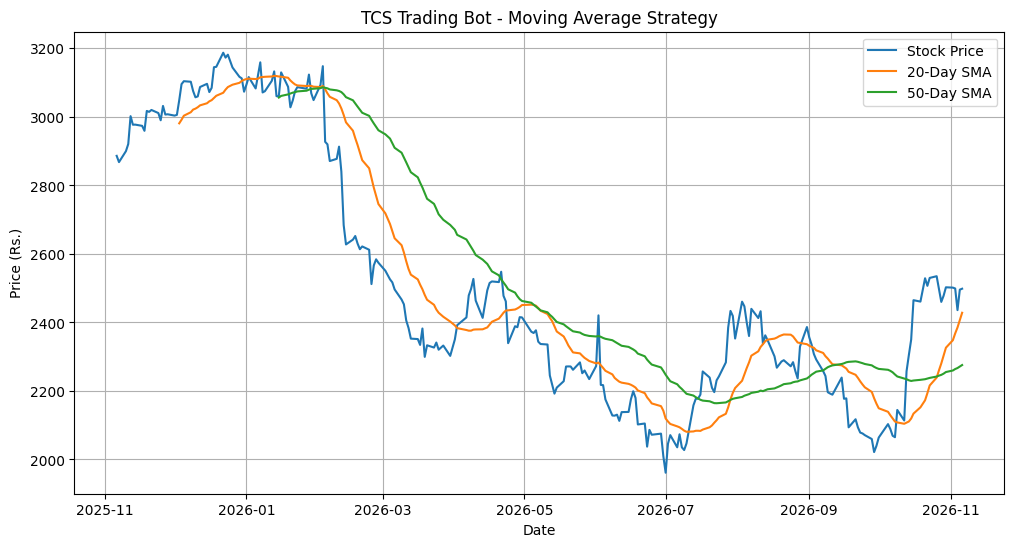

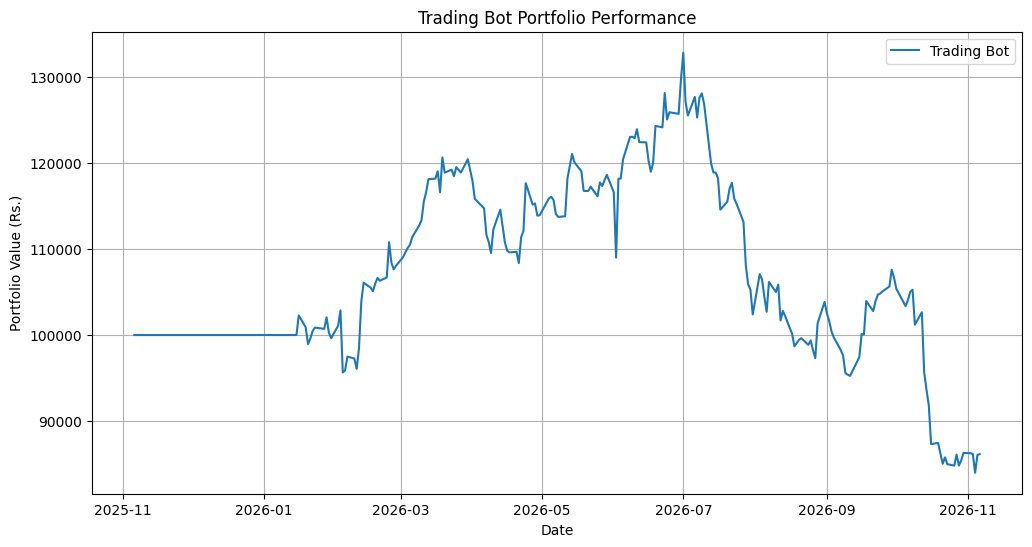


Trading Bot Executed Successfully!


In [ ]:

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 1. Download Stock Data
stock = "TCS.NS"

data = yf.download(
    stock,
    period="1y",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("Unable to download stock data.")

# 2. Fix Yahoo Finance columns
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

# 3. Calculate Moving Averages
data["SMA_20"] = data["Close"].rolling(20).mean()
data["SMA_50"] = data["Close"].rolling(50).mean()

# 4. Generate Trading Signals
data["Signal"] = 0

data.loc[data["SMA_20"] > data["SMA_50"], "Signal"] = 1
data.loc[data["SMA_20"] < data["SMA_50"], "Signal"] = -1

# Detect actual crossover events
data["Previous_Signal"] = data["Signal"].shift(1)

data["Action"] = "HOLD"

data.loc[
    (data["Signal"] == 1) &
    (data["Previous_Signal"] != 1),
    "Action"
] = "BUY"

data.loc[
    (data["Signal"] == -1) &
    (data["Previous_Signal"] != -1),
    "Action"
] = "SELL"

# 5. Calculate Strategy Returns
data["Daily_Return"] = data["Close"].pct_change()

data["Strategy_Return"] = (
    data["Signal"].shift(1) * data["Daily_Return"]
)

# 6. Calculate Portfolio Value
initial_amount = 100000

data["Bot_Value"] = initial_amount * (
    1 + data["Strategy_Return"].fillna(0)
).cumprod()

# 7. Display Results
print("====================================")
print("       TRADING BOT RESULTS")
print("====================================")

latest_price = float(data["Close"].iloc[-1])
latest_signal = int(data["Signal"].iloc[-1])

print("Stock Name:", stock)
print("Latest Date:", data.index[-1].date())
print("Closing Price: Rs.", round(latest_price, 2))

if latest_signal == 1:
    print("Current Strategy Signal: BUY")
elif latest_signal == -1:
    print("Current Strategy Signal: SELL")
else:
    print("Current Strategy Signal: HOLD")

print("\nRecent Trading Actions:")
print(data[["Close", "SMA_20", "SMA_50", "Action"]].tail(10))

# 8. Profit and Loss
final_value = float(data["Bot_Value"].iloc[-1])
profit = final_value - initial_amount

print("\nInitial Capital: Rs.", initial_amount)
print("Final Portfolio Value: Rs.", round(final_value, 2))
print("Profit / Loss: Rs.", round(profit, 2))

# 9. Plot Stock Price and Moving Averages
plt.figure(figsize=(12, 6))

plt.plot(data.index, data["Close"], label="Stock Price")
plt.plot(data.index, data["SMA_20"], label="20-Day SMA")
plt.plot(data.index, data["SMA_50"], label="50-Day SMA")

plt.title("TCS Trading Bot - Moving Average Strategy")
plt.xlabel("Date")
plt.ylabel("Price (Rs.)")
plt.legend()
plt.grid()
plt.show()

# 10. Plot Portfolio Performance
plt.figure(figsize=(12, 6))

plt.plot(data.index, data["Bot_Value"], label="Trading Bot")

plt.title("Trading Bot Portfolio Performance")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (Rs.)")
plt.legend()
plt.grid()
plt.show()

print("\nTrading Bot Executed Successfully!")

In [1]:
from google.colab import files
files.download('/content/Trading_Bot.ipynb')

FileNotFoundError: Cannot find file: /content/Trading_Bot.ipynb

In [2]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']
